# Part-C (Arabic Egypt Customer Reviews Dataset)

## Overview
The **Arabic Egypt Customer Reviews** dataset (`Arabic Egypt Customer Reviews.csv`) is a collection of customer feedback written primarily in **Egyptian Arabic**. This part focuses on dialectal Arabic, particularly sentiment analysis, opinion mining, and customer experience analytics.

---

## Dataset Details
* **Primary Language / Dialect:** Egyptian Arabic, with occasional Modern Standard Arabic and code-switching (Arabizi / English loanwords).
* **Domain:** Customer Reviews & Feedback (for example local services).
* **Total Records:** 40,046 records

---

## Description
The dataset consists of the following columns:

| Column Name | Data Type | Description |
| :--- | :--- | :--- |
| `Review_Description` | `String` | The raw text of the customer review in Egyptian Arabic. |
| `Rating` | `String` | Positive, or Negative review from Customers. |
| `Company` | `String` | The rating that came from the company application (for example talabat). |

---

## Key Characteristics of the Dataset
This data presents unique linguistic features that we should consider during preprocessing:
* **Dialectal Vocabulary & Idioms:** Contains everyday Egyptian expressions, slang, and negations (e.g., *مش*, *ما...ش*).
* **Code-Switching & Arabizi:** Includes mixed Arabic-English text and transliterated Arabic words using Latin characters and numbers.
* **Orthographic Variations:** Inconsistent spelling of characters such as *Alef* (`أ`, `إ`, `آ` $\rightarrow$ `ا`), *Ta Marbuta* (`ة` $\rightarrow$ `ه`), and *Ya* (`ي` $\rightarrow$ `ى`).
* **Informal Markers:** Heavy use of emojis, repeated characters for emphasis (elongation/stretching), and lack of diacritics (*Tashkeel*).

---

## Potential Use Cases
* **Sentiment Analysis:** Training binary or multi-class classifiers to detect customer satisfaction in Egyptian dialect.
* **Aspect-Based Sentiment Analysis:** Extracting sentiment toward specific attributes like product quality.
* **Dialect Identification & Translation:** Benchmarking dialectal Arabic models or building Egyptian-to-MSA / Egyptian-to-English translation pipelines.
* **Topic Modeling:** Discovering recurring customer complaints, feature requests, and trending themes.

In [1]:
# Important libraries for this Task.
import pandas as pd # Data Preprocessing
import numpy as np # Array and Numerical Processing
import matplotlib.pyplot as plt # Visualization
import seaborn as sns # Another Visualization (on top of matplotlib)
import re # For regular expression that enables text validation, parsing, and manipulation
from scipy import sparse # Another array and numerical processing (on top of numpy)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, precision_recall_fscore_support)

In [2]:
# Load the data

df = pd.read_csv('/content/Arabic_Egypt_Customer_Reviews.csv')
df = df[df["rating"].isin(["positive", "negative"])].copy() # neutral removed (neither satisfied nor not)
df["label"] = (df["rating"] == "positive").astype(int) # 1 = satisfied
df["raw"] = df["review_description"].astype(str)

# drop exact duplicate raw texts (prevents train/test leakage) -> same rows for every pipeline
df["_k"] = df["raw"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
df = df[df["_k"].str.contains(r"\w")].drop_duplicates("_k").reset_index(drop=True)
print("Rows used:", len(df), df["label"].value_counts(normalize=True).round(3).to_dict(), "(1 = satisfied)")

Rows used: 36234 {1: 0.619, 0: 0.381} (1 = satisfied)


In [3]:
# Replace each 'Positive' or 'Negative' with integer values
# 1: Positive, 0: Negative

df = df.dropna(subset=["review_description"]) # Dropping Nulls
df = df[df["rating"].isin(["positive", "negative"])].copy() # Just leave the Neutral one for this model
df["label"] = (df["rating"] == "positive").astype(int)
df = df.drop(['rating'], axis=1)
print(df.head())

                                  review_description company  label  \
0                                               رائع  talbat      1   
1  برنامج رائع جدا يساعد على تلبيه الاحتياجات بشك...  talbat      1   
2  التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...  talbat      0   
3                 لماذا لا يمكننا طلب من ماكدونالدز؟  talbat      0   
4  البرنامج بيظهر كل المطاعم و مغلقه مع انها بتكو...  talbat      0   

                                                 raw  \
0                                               رائع   
1  برنامج رائع جدا يساعد على تلبيه الاحتياجات بشك...   
2  التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...   
3                 لماذا لا يمكننا طلب من ماكدونالدز؟   
4  البرنامج بيظهر كل المطاعم و مغلقه مع انها بتكو...   

                                                  _k  
0                                               رائع  
1  برنامج رائع جدا يساعد على تلبيه الاحتياجات بشك...  
2  التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...  
3               

In [4]:
# Cleaning the data
HTML = re.compile(r"<[^>]+>") # Removing HTML tags form a sentence in the Dataset
URL = re.compile(r"http\S+|www\.\S+") # Removes web links
DIACRITICS = re.compile(r"[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED]") # Removing Tashkel and Quranic Words and map it to the same token
EMOJI = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF\u2764\u2B50\u2705]") # Removing Emojis from the wrods
NON_TEXT = re.compile(r"[^\w\s]|_", re.UNICODE) # Removing punctuations, emojis, and special symbols
DIGITS = re.compile(r"[0-9\u0660-\u0669\u06F0-\u06F9]+") # latin + arabic-indic digits
REPEAT = re.compile(r"(.)\1{2,}") # Detect repeated Arabic Characters
_HEX2LET = str.maketrans("0123456789abcdef", "ghijklmnopqrstuv") # Make character translation table hat maps the 16 hexadecimal characters (0–9, a–f) to the 16 lowercase letters 'g' through 'v'


def base_norm(s): # always-on Arabic normalisation (alef / ya' / ta'-marbuta)
    s = re.sub("[إأآا]", "ا", s)
    return s.replace("ى", "ي").replace("ة", "ه")

LETTER_MAP = str.maketrans({"ث": "ت", "ذ": "د", "ظ": "ض", "ؤ": "و", "ڤ": "ف", "چ": "ج", "گ": "ج", "ڨ": "ق"})
def char_norm(s, letters): # Egyptian spelling: ث/ت, ذ/د, ظ/ض are written interchangeably
    s = base_norm(s)
    return s.translate(LETTER_MAP) if letters else s

In [5]:
# Stop words

MSA_STOP = set("""
في من على الى إلى عن مع هذا هذه ذلك تلك هنا هناك هو هي هم هن انا انت انتم نحن أنا أنت التي الذي الذين
ما ماذا لماذا متى كيف اين أين اي أي كل بعض غير بعد قبل حتى اذا إذا لو ان أن إن انه أنه انها أنها كان كانت
يكون تكون كانوا قد لقد ثم او أو و ف ب ل ك لدى لدي عند عندما حيث بين خلال منذ فقط ايضا أيضا
علي عليه عليها عليهم منه منها منهم له لها لهم به بها بهم فيه فيها فيهم يا اما أما إما لكن لكنه لكنها بل ولا ولكن
""".split())
EGY_STOP = set("""
ده دي دا دة دى ديه دول دوول كده كدا كدة ازاي إزاي ايه إيه ايش ليه ليش فين امتى إمتى مين مين ازيك
عشان علشان عشانن اللي اللى لسه لسا لسة برضه برضو برده بقى بقي طب
انتي انتو احنا هما هم احنا دلوقتي دلوقت دلوقتى حاجه حاجة حاجات شوية شويه واحد واحدة حد
فى فيه فيها ف ع علي عليه عليها عليهم معاه معاها معاهم منه منها عنده عندها عندهم عندي عندك
اهو اهي اهم ايوه ايوا لما لسا هو هي ان إن انا انت انك انه انها يلا بتاع بتاعت بتاعه
كان كانت كانوا بقا بقت هيكون يبقى يبقي لو لو سواء
""".split())
KEEP = {"لا", "لم", "لن", "ليس", "مش", "ما", "غير", "بدون", "مفيش", "مافيش", "مو", "اوي", "خالص", "جدا", "كتير", "قوي"}

In [6]:
# Dialect spelling variants

_LEX = {
 "مفيش": "مافيش مفيش مافي مفيهوش مافيهوش مفيهاش مافيهاش مفيييش",
 "عايز": "عاوز عايز عاوزه عايزه عاوزين عايزين عايزة عاوزة",
 "اوي": "اوي اووي قوي اوى قوى",
 "كتير": "كتير كتيير كثير",
 "عشان": "علشان عشان عالشان عشانن",
 "ليه": "ليه ليش لييه ليهه",
 "كده": "كده كدا كدة كدي",
 "لسه": "لسه لسا لسة لسه",
 "برضه": "برضه برضو برده برضة",
 "وحش": "وحش وحشه وحشة وحشين",
 "حلو": "حلو حلوه حلوة حلوين",
 "سيء": "سيء سيئ سئ سيئه سيئة سء سيئين",
 "زباله": "زباله زبالة زبالا",
 "روعه": "روعه روعة روووعه",
 "ممتاز": "ممتاز ممتازه ممتازة ممتازين",
 "رائع": "رائع رائعه رائعة",
 "جميل": "جميل جميله جميلة جميلين",
 "كويس": "كويس كويسه كويسة كويسين",
 "تمام": "تمام تمااام",
 "دلوقتي": "دلوقتي دلوقت دلوقتى",
 "ايوه": "ايوه ايوا",
 "شغال": "شغال شغاله شغالة",
 "بطيء": "بطيء بطئ بطيئ بطيئه بطيئة",
}

LEXICON = {base_norm(v): base_norm(k) for k, vs in _LEX.items() for v in vs.split()}
NEG_CIRCUM = re.compile(r"^(?:ما|م)(.{2,}?)ش$") # مبيفتحش / ماينفعش / مجاش  ->  مش + stem
DIAL_PREFIX = [(re.compile(r"^(?:بي|هي)(.{3,})$"), r"ي\1"),
               (re.compile(r"^(?:بت|هت)(.{3,})$"), r"ت\1"),
               (re.compile(r"^(?:بن|هن)(.{3,})$"), r"ن\1"),
               (re.compile(r"^(?:با|ها)(.{3,})$"), r"ا\1")]
AL_PREFIX = re.compile(r"^(?:وال|بال|كال|فال|لل|ال)(.{3,})$")

In [7]:
# Process the dialect spelling variants and stop words

def make_stop(cfg):
    base = (MSA_STOP | EGY_STOP) if cfg["egy_stop"] else MSA_STOP
    return {char_norm(w, cfg["letters"]) for w in base - KEEP} - {char_norm(w, cfg["letters"]) for w in KEEP}

def make_cleaner(cfg):
    stop = make_stop(cfg)
    def clean(text):
        t = str(text).lower() # lowercase (latin letters)
        t = HTML.sub(" ", t); t = URL.sub(" ", t) # HTML tags, URLs
        t = DIACRITICS.sub("", t).replace("ـ", "") # tashkeel, tatweel
        if cfg["emoji"]: # keep emojis as word-tokens
            t = EMOJI.sub(lambda m: " emo" + format(ord(m.group()), "x").translate(_HEX2LET) + " ", t)
        t = NON_TEXT.sub(" ", t) # punctuation / symbols
        t = DIGITS.sub(" ", t) # numbers
        t = REPEAT.sub(r"\1", t) # رااائع / اوووي -> رائع / اوي
        t = base_norm(t)
        toks = t.split()
        if cfg["lex"]: # dialect spelling variants
            toks = [LEXICON.get(w, w) for w in toks]
        if cfg["letters"]:
            toks = [w.translate(LETTER_MAP) for w in toks]
        if cfg["neg"]: # Egyptian circumfix negation  ما...ش
            out = []
            for w in toks:
                m = NEG_CIRCUM.match(w) if (w not in ("مفيش", "مش", "مافيش") and len(w) >= 4) else None
                out += ["مش", m.group(1)] if m else [w]
            toks = out
        toks = [w for w in toks if w not in stop and len(w) > 1] # stopwords
        if cfg["prefix"]: # بيفتح / هيوصل / بتشتغل -> يفتح / يوصل / تشتغل
            new = []
            for w in toks:
                if len(w) >= 5 and not w.startswith("emo"):
                    for rx, rep in DIAL_PREFIX:
                        if rx.match(w):
                            w = rx.sub(rep, w); break
                new.append(w)
            toks = new
        if cfg["stem"]: # light stemming: ال / و / final ه
            new = []
            for w in toks:
                if not w.startswith("emo") and w.isascii() is False:
                    m = AL_PREFIX.match(w)
                    if m: w = m.group(1)
                    if len(w) >= 5 and w[0] == "و": w = w[1:]
                    if len(w) >= 4 and w.endswith("ه"): w = w[:-1]
                new.append(w)
            toks = new
        return " ".join(w for w in toks if len(w) > 1)
    return clean

In [8]:
print(df.head())

                                  review_description company  label  \
0                                               رائع  talbat      1   
1  برنامج رائع جدا يساعد على تلبيه الاحتياجات بشك...  talbat      1   
2  التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...  talbat      0   
3                 لماذا لا يمكننا طلب من ماكدونالدز؟  talbat      0   
4  البرنامج بيظهر كل المطاعم و مغلقه مع انها بتكو...  talbat      0   

                                                 raw  \
0                                               رائع   
1  برنامج رائع جدا يساعد على تلبيه الاحتياجات بشك...   
2  التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...   
3                 لماذا لا يمكننا طلب من ماكدونالدز؟   
4  البرنامج بيظهر كل المطاعم و مغلقه مع انها بتكو...   

                                                  _k  
0                                               رائع  
1  برنامج رائع جدا يساعد على تلبيه الاحتياجات بشك...  
2  التطبيق لا يغتح دائما بيعطيني لا يوجد اتصال با...  
3               

In [9]:
# Splitting the data after cleaning

SEED = 42

y_all = df["label"].values
idx = np.arange(len(df))
i_tr, i_tmp = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=SEED)
i_val, i_te = train_test_split(i_tmp, test_size=0.50, stratify=y_all[i_tmp], random_state=SEED)
y_tr, y_val, y_te = y_all[i_tr], y_all[i_val], y_all[i_te]
print(f"Train {len(i_tr)} | Val {len(i_val)} | Test {len(i_te)}")
raw = df["raw"].values

MAX_FEATURES = 20000
def make_vec():
    return TfidfVectorizer(ngram_range=(1, 2), max_features=MAX_FEATURES, min_df=2, sublinear_tf=True)

def val_score(cfg, C=3.0):
    """Fit cleaning->TF-IDF on TRAIN, score on VALIDATION (test never touched here)."""
    cl = make_cleaner(cfg)
    tr = [cl(t) for t in raw[i_tr]]; va = [cl(t) for t in raw[i_val]]
    v = make_vec(); Xa = v.fit_transform(tr); Xb = v.transform(va)
    p = LogisticRegression(C=C, max_iter=2000, random_state=SEED).fit(Xa, y_tr).predict(Xb)
    return precision_recall_fscore_support(y_val, p, average="macro")[2], accuracy_score(y_val, p)

Train 25363 | Val 5435 | Test 5435


In [10]:
# This measures how much each dialect-specific text cleaning step improves model performance (valdation dataset only)

STEPS = [("egy_stop", "Egyptian stopwords (ده، كده، ازاي، عشان…)"),
         ("emoji",    "keep emojis as tokens"),
         ("lex",      "dialect spelling variants (مافيش/مفيش، عاوز/عايز، قوي/اوي…)"),
         ("letters",  "Egyptian letter spelling (ث→ت، ذ→د، ظ→ض)"),
         ("neg",      "negation circumfix (مبيفتحش → مش يفتح)"),
         ("prefix",   "dialect verb prefixes (بيـ/بتـ/هيـ…)"),
         ("stem",     "light stemming (ال، و، final ه)")]
cfg = {k: True for k, _ in STEPS} # the Egyptian pipeline uses ALL dialect steps by design
acc_cfg = {k: False for k, _ in STEPS}
f1, acc = val_score(acc_cfg)
rows = [("MSA-style baseline (all dialect steps off)", f1, acc)]
print(f"\nBaseline (MSA-style cleaning): val macro-F1={f1:.4f}  acc={acc:.4f}")
for key, desc in STEPS: # cumulative ablation, VALIDATION set only (informational)
    acc_cfg[key] = True
    f1, acc = val_score(acc_cfg)
    print(f"  + {desc:<62s} val F1={f1:.4f} acc={acc:.4f}")
    rows.append((f"+ {desc}", f1, acc))


Baseline (MSA-style cleaning): val macro-F1=0.8727  acc=0.8813
  + Egyptian stopwords (ده، كده، ازاي، عشان…)                      val F1=0.8726 acc=0.8813
  + keep emojis as tokens                                          val F1=0.8742 acc=0.8828
  + dialect spelling variants (مافيش/مفيش، عاوز/عايز، قوي/اوي…)    val F1=0.8741 acc=0.8828
  + Egyptian letter spelling (ث→ت، ذ→د، ظ→ض)                       val F1=0.8734 acc=0.8821
  + negation circumfix (مبيفتحش → مش يفتح)                         val F1=0.8738 acc=0.8824
  + dialect verb prefixes (بيـ/بتـ/هيـ…)                           val F1=0.8740 acc=0.8826
  + light stemming (ال، و، final ه)                                val F1=0.8776 acc=0.8857


In [11]:
# build features for both pipelines (fit on train dataset only)

def build(c):
    cl = make_cleaner(c)
    tr = [cl(t) for t in raw[i_tr]]; va = [cl(t) for t in raw[i_val]]; te = [cl(t) for t in raw[i_te]]
    v = make_vec(); Xa = v.fit_transform(tr)
    return v, Xa, v.transform(va), v.transform(te) # test is only transformed, never fit
MSA_CFG = {k: False for k, _ in STEPS}
vec_m, Xtr_m, Xval_m, Xte_m = build(MSA_CFG)
vec_e, Xtr_e, Xval_e, Xte_e = build(cfg)
print("TF-IDF vocabulary size -> MSA:", len(vec_m.vocabulary_), "| Egyptian:", len(vec_e.vocabulary_))

TF-IDF vocabulary size -> MSA: 20000 | Egyptian: 20000



Egyptian pipeline - Logistic Regression: best C = 3.0
     C  val_acc  val_macroF1
  0.01   0.6583       0.4871
  0.03   0.7921       0.7479
  0.10   0.8559       0.8392
  0.30   0.8754       0.8648
  1.00   0.8826       0.8738
  3.00   0.8857       0.8776
 10.00   0.8824       0.8744
 30.00   0.8749       0.8662
100.00   0.8646       0.8552

Egyptian pipeline - Linear SVM: best C = 0.3
     C  val_acc  val_macroF1
  0.01   0.8521       0.8340
  0.03   0.8753       0.8644
  0.10   0.8810       0.8719
  0.30   0.8848       0.8766
  1.00   0.8795       0.8712
  3.00   0.8662       0.8569
 10.00   0.8488       0.8383
 30.00   0.8344       0.8230
100.00   0.8305       0.8187

MSA baseline - Logistic Regression: best C = 3.0
     C  val_acc  val_macroF1
  0.01   0.6237       0.3967
  0.03   0.7676       0.7098
  0.10   0.8396       0.8191
  0.30   0.8666       0.8544
  1.00   0.8780       0.8685
  3.00   0.8813       0.8727
 10.00   0.8754       0.8669
 30.00   0.8684       0.8596
100.00  

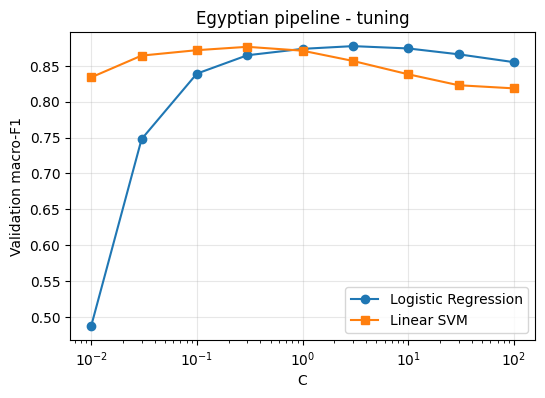

In [12]:
# hyperparameters tuning (validation dataset only)

GRID = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]
def tune(make, Xa, Xv, name):
    r = []
    for c in GRID:
        p = make(c).fit(Xa, y_tr).predict(Xv)
        r.append((c, accuracy_score(y_val, p), precision_recall_fscore_support(y_val, p, average="macro")[2]))
    t = pd.DataFrame(r, columns=["C", "val_acc", "val_macroF1"])
    b = t.sort_values(["val_macroF1", "val_acc"], ascending=False).iloc[0]["C"]
    print(f"\n{name}: best C = {b}\n{t.round(4).to_string(index=False)}")
    return b, t
mk_lr = lambda c: LogisticRegression(C=c, max_iter=2000, random_state=SEED)
mk_svm = lambda c: LinearSVC(C=c, random_state=SEED, max_iter=10000)
C_lr_e, t_lr = tune(mk_lr, Xtr_e, Xval_e, "Egyptian pipeline - Logistic Regression")
C_svm_e, t_svm = tune(mk_svm, Xtr_e, Xval_e, "Egyptian pipeline - Linear SVM")
C_lr_m, _ = tune(mk_lr, Xtr_m, Xval_m, "MSA baseline - Logistic Regression")
C_svm_m, _ = tune(mk_svm, Xtr_m, Xval_m, "MSA baseline - Linear SVM")

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogx(t_lr["C"], t_lr["val_macroF1"], "o-", label="Logistic Regression")
ax.semilogx(t_svm["C"], t_svm["val_macroF1"], "s-", label="Linear SVM")
ax.set_xlabel("C"); ax.set_ylabel("Validation macro-F1"); ax.set_title("Egyptian pipeline - tuning"); ax.legend(); ax.grid(alpha=.3)

lr_e = mk_lr(C_lr_e).fit(Xtr_e, y_tr); svm_e = mk_svm(C_svm_e).fit(Xtr_e, y_tr)
lr_m = mk_lr(C_lr_m).fit(Xtr_m, y_tr); svm_m = mk_svm(C_svm_m).fit(Xtr_m, y_tr)

In [13]:
# BONUS: Ensembel approach

nb_sc = [(a, precision_recall_fscore_support(y_val, MultinomialNB(alpha=a).fit(Xtr_e, y_tr).predict(Xval_e), average="macro")[2])
         for a in [0.01, 0.03, 0.1, 0.3, 1.0]]
a_nb = max(nb_sc, key=lambda s: s[1])[0]
vote = VotingClassifier([("lr", mk_lr(C_lr_e)), ("svm", mk_svm(C_svm_e)), ("nb", MultinomialNB(alpha=a_nb))],
                        voting="hard").fit(Xtr_e, y_tr)
print("\nNaive-Bayes alpha (val):", a_nb)


Naive-Bayes alpha (val): 0.3


NumPy LR best on val: macro-F1=0.8768 lr=1.0 l2=1e-06


Text(0, 0.5, 'train loss')

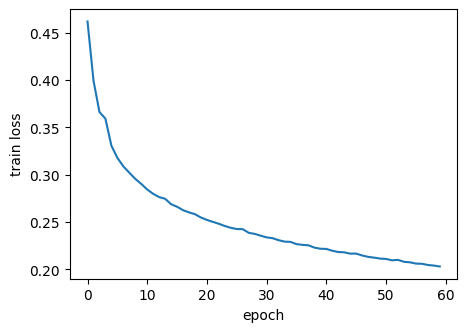

In [14]:
# BONUS: Implementing numpy with logistic regression from scratch

class NumpyLogReg:
    def __init__(self, lr=0.5, epochs=60, l2=1e-4, batch=256, momentum=0.9, seed=SEED):
        self.lr, self.epochs, self.l2, self.batch, self.mom, self.seed = lr, epochs, l2, batch, momentum, seed
    @staticmethod
    def _sig(z): return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))
    def fit(self, X, y):
        rng = np.random.RandomState(self.seed); n, d = X.shape
        self.w, self.b = np.zeros(d), 0.0; vw, vb = np.zeros(d), 0.0; self.loss_hist = []
        for _ in range(self.epochs):
            perm = rng.permutation(n)
            for s in range(0, n, self.batch):
                bi = perm[s:s + self.batch]; Xb, yb = X[bi], y[bi]
                err = self._sig(Xb @ self.w + self.b) - yb
                gw = (Xb.T @ err) / len(bi) + self.l2 * self.w; gb = err.mean()
                vw = self.mom * vw - self.lr * gw; vb = self.mom * vb - self.lr * gb
                self.w += vw; self.b += vb
            p = np.clip(self._sig(X @ self.w + self.b), 1e-12, 1 - 1e-12)
            self.loss_hist.append(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)) + 0.5 * self.l2 * self.w @ self.w)
        return self
    def predict(self, X): return (self._sig(X @ self.w + self.b) >= 0.5).astype(int)

best = None
for lr_ in [0.1, 0.5, 1.0]:
    for l2_ in [1e-6, 1e-5, 1e-4]:
        f = precision_recall_fscore_support(y_val, NumpyLogReg(lr=lr_, l2=l2_, epochs=30).fit(Xtr_e, y_tr).predict(Xval_e), average="macro")[2]
        if best is None or f > best[0]: best = (f, lr_, l2_)
print(f"NumPy LR best on val: macro-F1={best[0]:.4f} lr={best[1]} l2={best[2]}")
np_lr = NumpyLogReg(lr=best[1], l2=best[2], epochs=60).fit(Xtr_e, y_tr)
plt.figure(figsize=(5, 3.5)); plt.plot(np_lr.loss_hist); plt.xlabel("epoch"); plt.ylabel("train loss")

In [15]:
# Final test evaluation

OUT = "/content/sample_data"

models = {"MSA baseline - LR": (lr_m, Xte_m), "MSA baseline - SVM": (svm_m, Xte_m),
          "Egyptian - LR (sklearn)": (lr_e, Xte_e), "Egyptian - Linear SVM": (svm_e, Xte_e),
          "Egyptian - Voting (LR+SVM+NB)": (vote, Xte_e), "Egyptian - LR (NumPy scratch)": (np_lr, Xte_e)}
CLS = ["Not satisfied (0)", "Satisfied (1)"]
summary, rep = [], []
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (nm, (m, Xt)) in zip(axes.ravel(), models.items()):
    pred = m.predict(Xt); acc = accuracy_score(y_te, pred); cm = confusion_matrix(y_te, pred)
    p, r, f, _ = precision_recall_fscore_support(y_te, pred)
    summary.append({"Model": nm, "Accuracy": acc, "Macro-F1": f.mean(), "P(neg)": p[0], "R(neg)": r[0], "F1(neg)": f[0],
                    "P(pos)": p[1], "R(pos)": r[1], "F1(pos)": f[1]})
    rep.append(f"=== {nm} ===\nAccuracy: {acc:.4f}\nConfusion matrix (rows=true, cols=pred):\n{cm}\n"
               + classification_report(y_te, pred, target_names=CLS, digits=4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not sat.", "Satisfied"], yticklabels=["Not sat.", "Satisfied"])
    ax.set_title(f"{nm}\nacc={acc:.4f}", fontsize=10); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.savefig(OUT + "egy_confusion_matrices.png", dpi=150); plt.close()
res = pd.DataFrame(summary).round(4)
print("\n" + "\n".join(rep)); print("\nSUMMARY (test set)\n", res.to_string(index=False))
print(f"\nNumPy LR vs sklearn LR agreement on test: {(np_lr.predict(Xte_e) == lr_e.predict(Xte_e)).mean():.4f}")
res.to_csv(OUT + "egy_test_results_summary.csv", index=False)
with open(OUT + "egy_test_results_report.txt", "w") as fh:
    fh.write(f"TF-IDF vocabulary size: Egyptian={len(vec_e.vocabulary_)}, MSA={len(vec_m.vocabulary_)} (max_features={MAX_FEATURES}, 1-2 grams, min_df=2)\n")
    fh.write(f"Egyptian cleaning steps kept: {[k for k, v in cfg.items() if v]}\n")
    fh.write(f"Split train/val/test = {len(i_tr)}/{len(i_val)}/{len(i_te)} (stratified, seed {SEED})\n")
    fh.write(f"Best C: Egy LR={C_lr_e}, Egy SVM={C_svm_e}, MSA LR={C_lr_m}, MSA SVM={C_svm_m}; NB alpha={a_nb}; NumPy lr={best[1]}, l2={best[2]}\n\n")
    fh.write("\n".join(rep) + "\n" + res.to_string(index=False))


=== MSA baseline - LR ===
Accuracy: 0.8815
Confusion matrix (rows=true, cols=pred):
[[1699  372]
 [ 272 3092]]
                   precision    recall  f1-score   support

Not satisfied (0)     0.8620    0.8204    0.8407      2071
    Satisfied (1)     0.8926    0.9191    0.9057      3364

         accuracy                         0.8815      5435
        macro avg     0.8773    0.8698    0.8732      5435
     weighted avg     0.8809    0.8815    0.8809      5435

=== MSA baseline - SVM ===
Accuracy: 0.8828
Confusion matrix (rows=true, cols=pred):
[[1701  370]
 [ 267 3097]]
                   precision    recall  f1-score   support

Not satisfied (0)     0.8643    0.8213    0.8423      2071
    Satisfied (1)     0.8933    0.9206    0.9067      3364

         accuracy                         0.8828      5435
        macro avg     0.8788    0.8710    0.8745      5435
     weighted avg     0.8822    0.8828    0.8822      5435

=== Egyptian - LR (sklearn) ===
Accuracy: 0.8861
Confusion mat

In [16]:
# Interpretation + dialect demo

fn = np.array(vec_e.get_feature_names_out()); co = lr_e.coef_[0]
print("\nTop 'satisfied' terms:", list(fn[np.argsort(co)[-15:][::-1]]))
print("Top 'not satisfied' terms:", list(fn[np.argsort(co)[:15]]))
cl = make_cleaner(cfg)
demo = ["التطبيق مبيفتحش خالص ومفيش حد بيرد عليا", "الاكل حلو اوي والتوصيل سريع تسلم ايديكوا",
        "وحش اوي مش هطلب تاني ابدا", "خدمة عملاء زفت بجد 👎", "تطبيق جامد جدا 😍👍"]
print("\nDialect examples (cleaned -> prediction):")
for s in demo:
    print(f"  {s}\n    -> {cl(s)}  =>  {'1' if lr_e.predict(vec_e.transform([cl(s)]))[0] else '0'}")


Top 'satisfied' terms: ['ممتاز', 'رائع', 'جميل', 'شكرا', 'روع', 'جيد', 'افضل', 'سريع', 'محترم', 'حلو', 'سهل', 'اجمل', 'اروع', 'احسن', 'احلي']
Top 'not satisfied' terms: ['سيء', 'فاشل', 'زبال', 'اسوء', 'اسوا', 'زفت', 'نجم', 'غير', 'اسف', 'ساعتين', 'emohvkku', 'اعلانات', 'حرامي', 'مش', 'لا']

Dialect examples (cleaned -> prediction):
  التطبيق مبيفتحش خالص ومفيش حد بيرد عليا
    -> تطبيق مش يفتح خالص مفيش بيرد عليا  =>  0
  الاكل حلو اوي والتوصيل سريع تسلم ايديكوا
    -> اكل حلو اوي توصيل سريع تسلم ايديكوا  =>  1
  وحش اوي مش هطلب تاني ابدا
    -> وحش اوي مش هطلب تاني ابدا  =>  0
  خدمة عملاء زفت بجد 👎
    -> خدم عملاء زفت بجد emohvkku  =>  0
  تطبيق جامد جدا 😍👍
    -> تطبيق جامد جدا emohvmgt emohvkkt  =>  1
